In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

import import_ipynb
import os

curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from BaseDataSet_Gen import NanoparticleDataFactory, plot_cn_distribution, plot_dataset_variability, plot_substructure_audit, get_preserved_mask
os.chdir(curdir)

## Загрузим данные и определим необходимые переменные

In [2]:
SPECTRA_ROOT = Path('../processed_data/conv_dense_spectra/')

FIG_SAVE_PATH = Path('../images/')
N_SAMPLES = 10000

UNIQUE_SUBSTRUCTURES = pd.read_pickle('../source_data/INIT_unique_substructures_Rcut_7.5_stephist_0.1.pkl')
# UNIQUE_SUBSTRUCTURES.head(3)

SUB_SIZES = UNIQUE_SUBSTRUCTURES.Num_atoms.values

NP_BASIS_DF = pd.read_pickle('../source_data/NP_basis_representation_from_substructures.pkl')
# NP_BASIS_DF.head(3)

WEIGHTS_MATRIX = np.stack(NP_BASIS_DF['Weighted_vector'].values)
NP_SIZES = WEIGHTS_MATRIX.sum(axis=1).astype(int)

NORMALISED_WEIGHTS = WEIGHTS_MATRIX / WEIGHTS_MATRIX.sum(axis=1, keepdims=True)

## Проверка влияния метода Разбиения на возможность утечки данных в реальных НЧ.

In [4]:
# Инициализация фабрики
e_grid = np.arange(-10, 100.1, 0.5) # Задаем сетку энергии для XANES спектров
factory = NanoparticleDataFactory(energy_grid=e_grid)

In [5]:
# Загрузка базиса
# Мы извлекаем CN для 7 сфер и интерполируем спектры
factory.load_basis(spectra_dir=SPECTRA_ROOT, 
                   substruct_df=UNIQUE_SUBSTRUCTURES, 
                   n_spheres=7 # Контроль кол-ва сфер.
                  )


Готово. В базисе 2151 подструктур.


### Сценарий 1: Герерируем случайные НЧ из всех доступных подструктур, потом делим на трейн и тест, и смотрим сколько подструктур из теста попали в трейн (как было предложено в работе J.Timoshenko 2017 (Kmix=3), test:20%).

Тест Колмогорова-Смирнова  для размеров НК (Train==Test): 0.00754 | P-value: 0.94577
Тест Колмогорова-Смирнова  для размеров НК (Train>=Test): 0.00754 | P-value: 0.57577
Число уникальных подструктур задействованных в трейн части = 2151
Число уникальных подструктур задействованных в тест части = 2017
Число уникальных подструктур из тест части не встречающихся в трейне = 0
Число уникальных подструктур из трейн части не встречающихся в тесте = 134


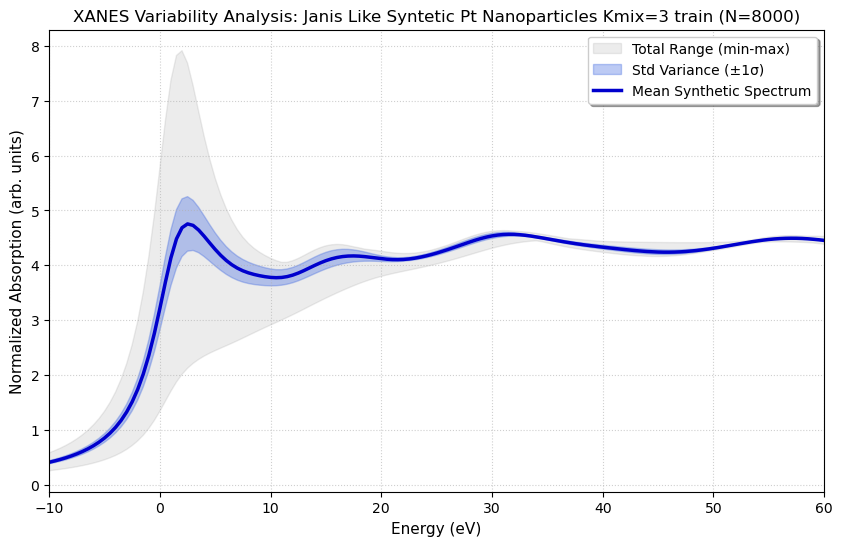

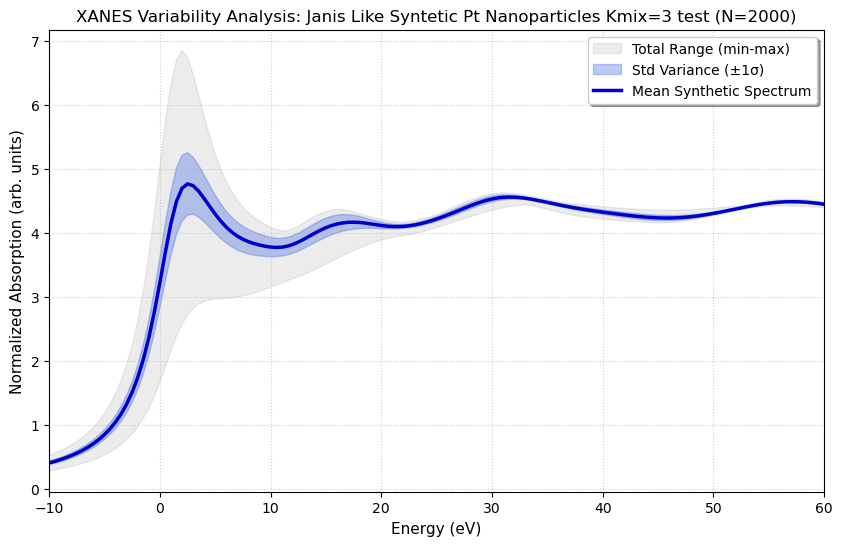

Y_train:


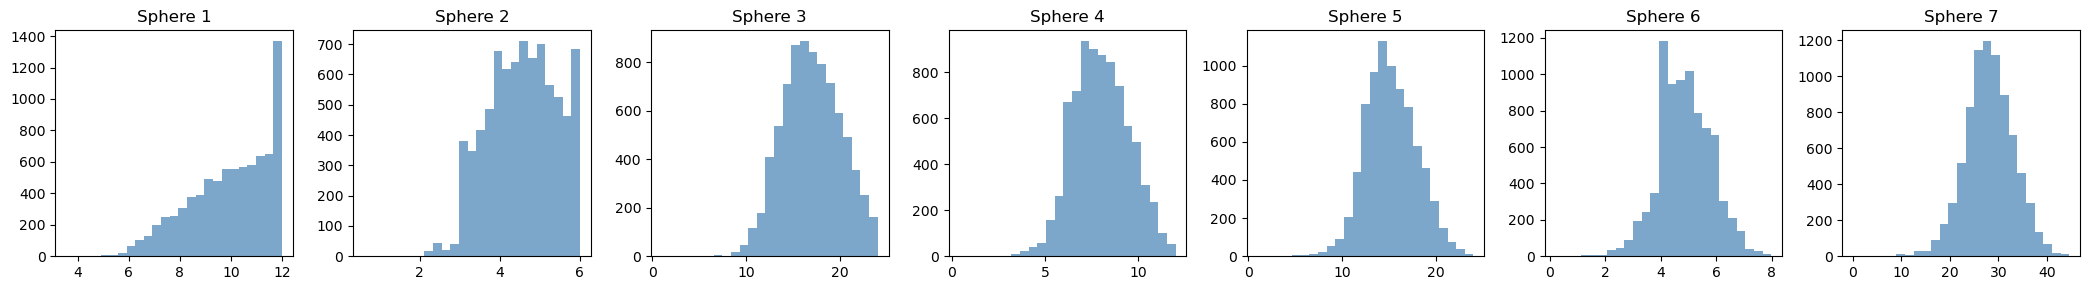

Y_test:


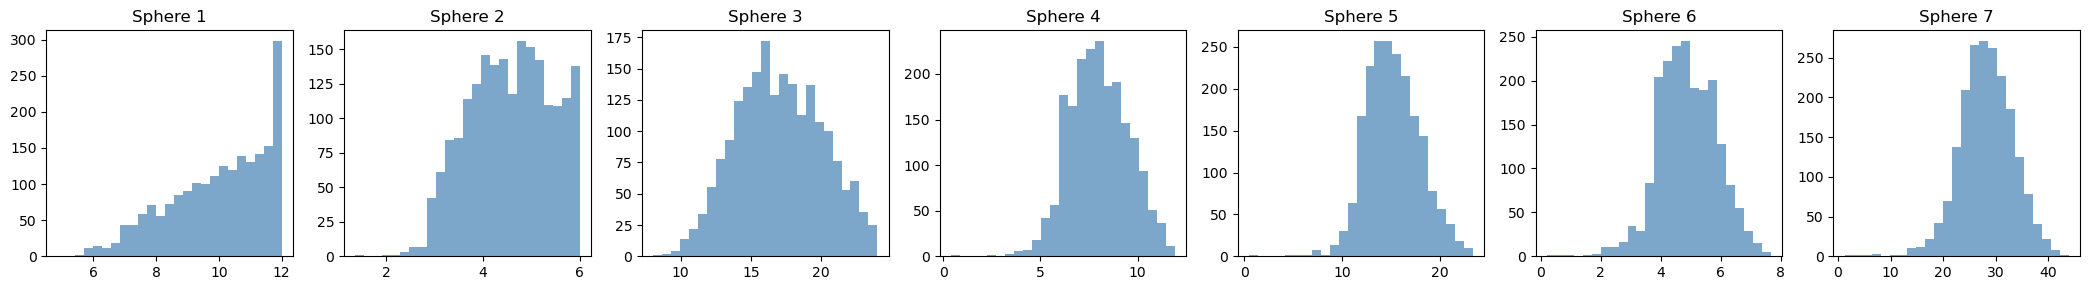

Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


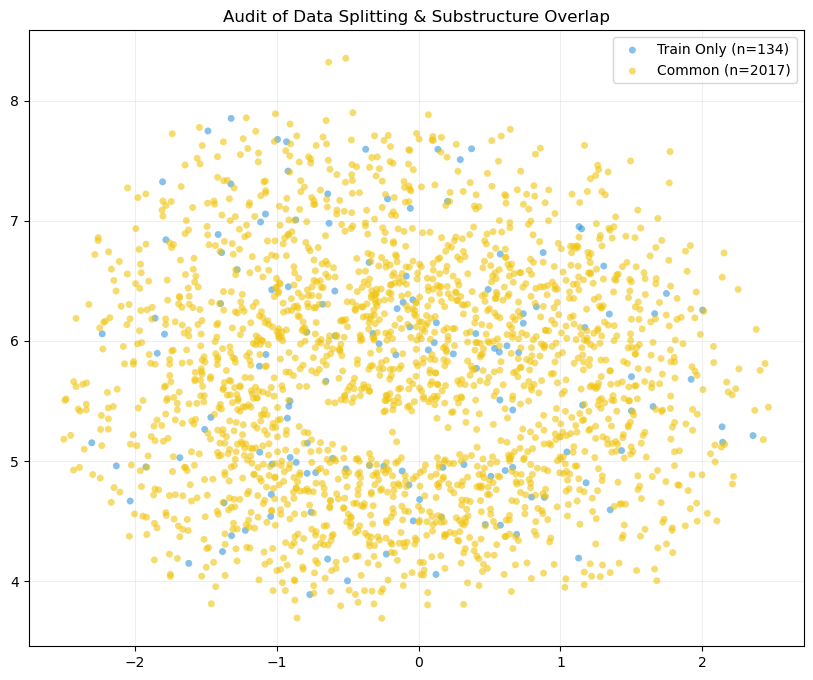

Запуск UMAP (может занять время)...


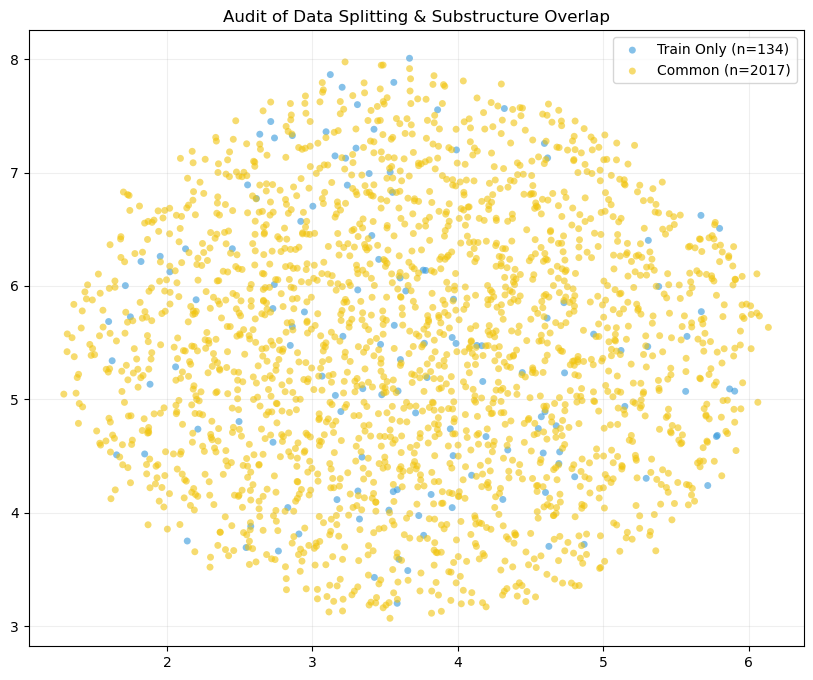

CPU times: total: 3min 37s
Wall time: 2min 9s


In [6]:
%%time
K_mix=3
save_name = str(Path(FIG_SAVE_PATH,f'Janis_like_procedure_subs_connectivities'))
train_weights = factory.create_synthetic_mix(n_samples=N_SAMPLES, 
                                             k_range=(K_mix, K_mix), 
                                             pool_indices=None
                                            )

# Получаем X-спектры и y-векторы CN по 7 сферам
# аугментации спектров не применяются.
X_km, y_km = factory.generate_experiment_data(train_weights, aug_params=None)
indeces = np.arange(train_weights.shape[0]).astype(int)
X_tr,X_te,y_tr,y_te,ind_tr, ind_te = train_test_split(X_km, y_km, indeces, test_size=0.20, random_state=42)

tr_sub_ind = np.where(train_weights[ind_tr]>0)[1].tolist()
te_sub_ind = np.where(train_weights[ind_te]>0)[1].tolist()

train_sub_sizes = SUB_SIZES[tr_sub_ind]
test_sub_sizes = SUB_SIZES[te_sub_ind]
sub_ks_stat_ts, sub_p_value_ts = ks_2samp(train_sub_sizes, test_sub_sizes, alternative='two-sided', method='asymp')
sub_ks_stat_gr, sub_p_value_gr = ks_2samp(train_sub_sizes, test_sub_sizes, alternative='greater', method='asymp')

print(f"Тест Колмогорова-Смирнова  для размеров НК (Train==Test): {sub_ks_stat_ts:.5f} | P-value: {sub_p_value_ts:.5f}")
print(f"Тест Колмогорова-Смирнова  для размеров НК (Train>=Test): {sub_ks_stat_gr:.5f} | P-value: {sub_p_value_gr:.5f}")

print(f'Число уникальных подструктур задействованных в трейн части = {len(set(tr_sub_ind))}')
print(f'Число уникальных подструктур задействованных в тест части = {len(set(te_sub_ind))}')
print(f'Число уникальных подструктур из тест части не встречающихся в трейне = {len(set(te_sub_ind)-set(tr_sub_ind))}')
print(f'Число уникальных подструктур из трейн части не встречающихся в тесте = {len(set(tr_sub_ind)-set(te_sub_ind))}')

# Отрисуем вариантивность спектров при такой генерации.
plot_dataset_variability(X_data=X_tr, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Janis Like Syntetic Pt Nanoparticles Kmix={K_mix} train",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_te, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Janis Like Syntetic Pt Nanoparticles Kmix={K_mix} test",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_tr,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_te,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=train_weights, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='dice', 
                        save_name=save_name+'_dice')


plot_substructure_audit(weights_matrix=train_weights, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='cosine', 
                        save_name=save_name+'_cosine')

### Сценарий 2: Случайное разбиение реальных НЧ на трейн и тест

Тест Колмогорова-Смирнова  для размеров НК (Train==Test): 0.01170 | P-value: 0.48116
Тест Колмогорова-Смирнова  для размеров НК (Train>=Test): 0.00164 | P-value: 0.97151
Тест Колмогорова-Смирнова  для размеров НЧ (Train==Test): 0.07031 | P-value: 0.52835
Тест Колмогорова-Смирнова  для размеров НЧ (Train>=Test): 0.03750 | P-value: 0.67706
Число уникальных подструктур задействованных в трейн части = 2040
Число уникальных подструктур задействованных в тест части = 566
Число уникальных подструктур из тест части не встречающихся в трейне = 111
Число уникальных подструктур из трейн части не встречающихся в тесте = 1585


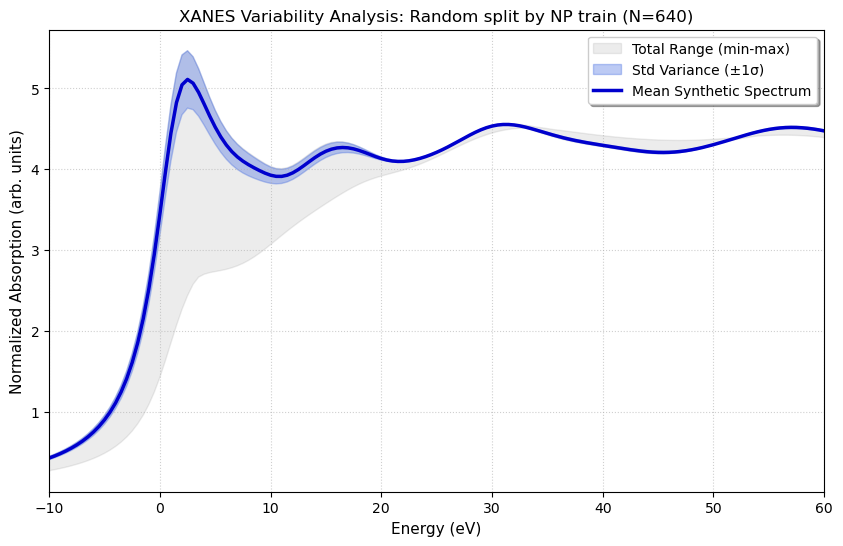

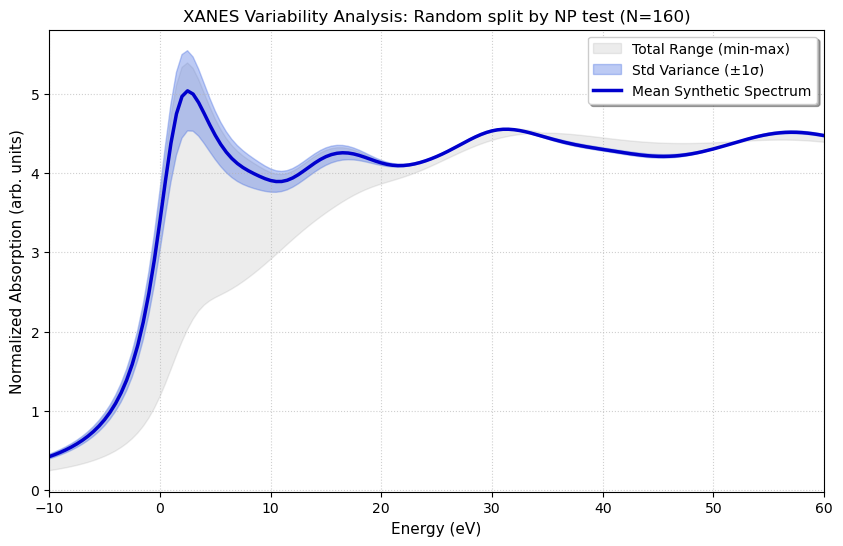

Y_train:


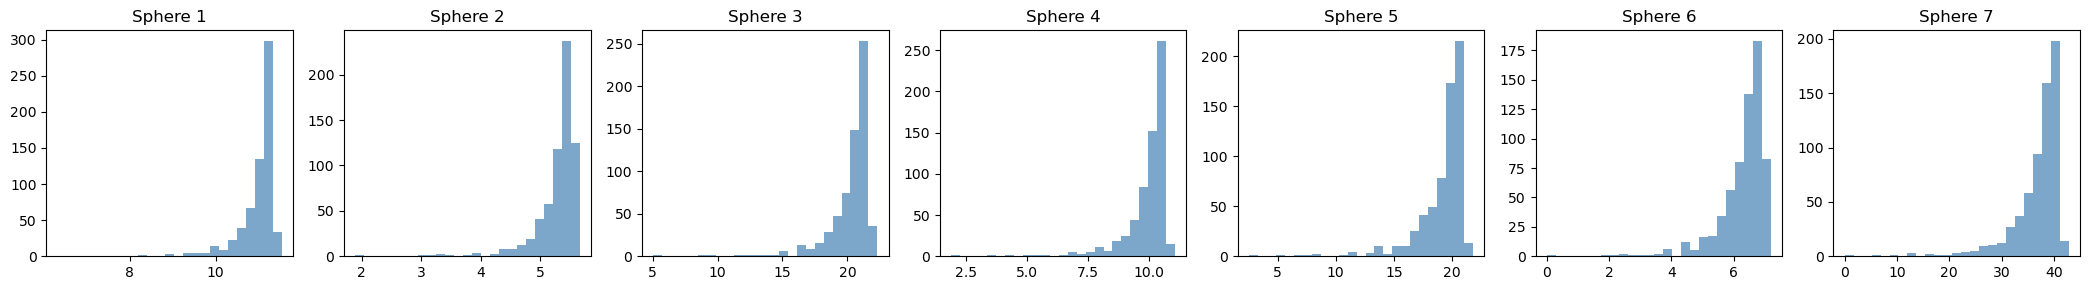

Y_test:


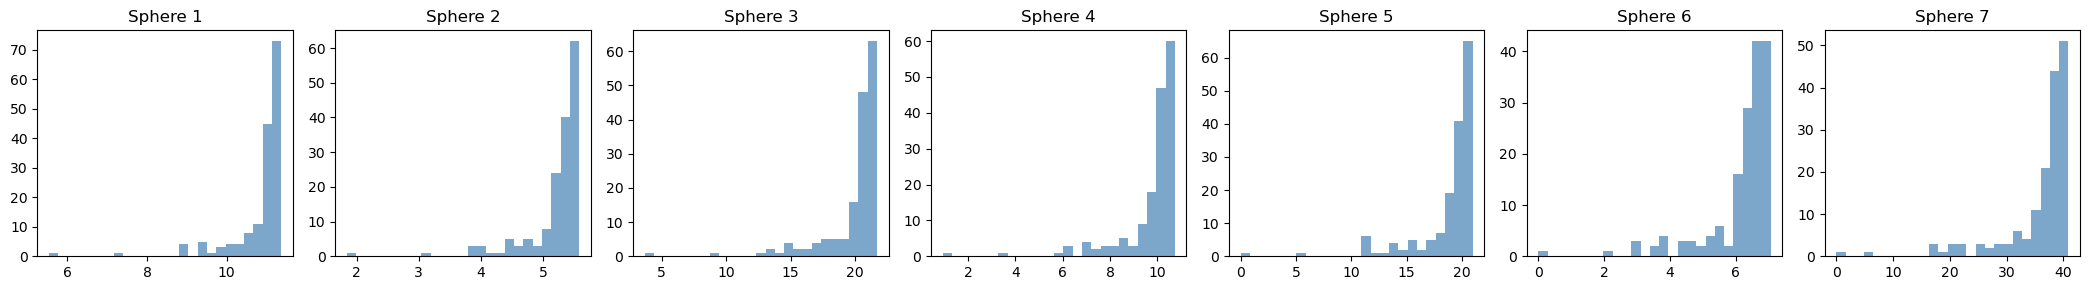

Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


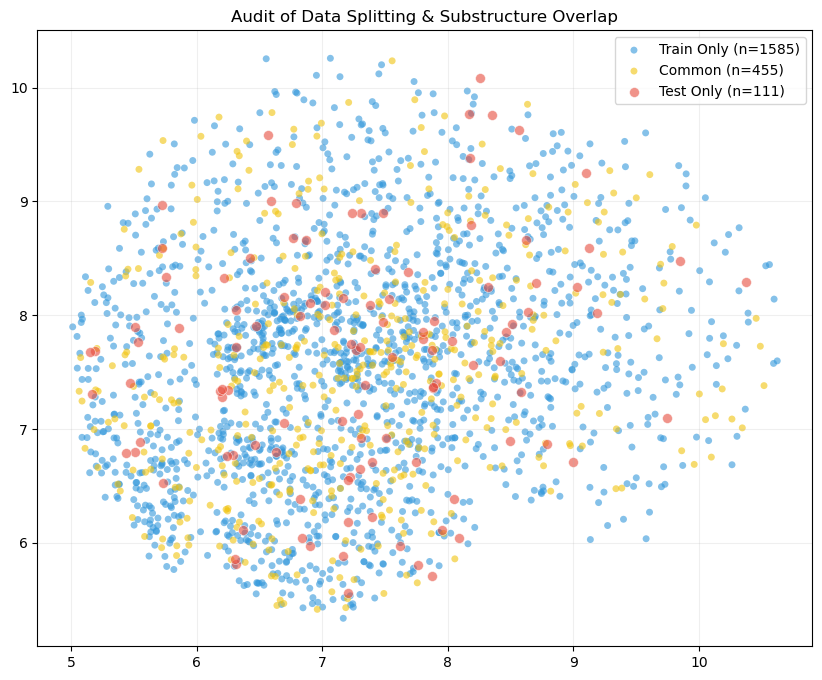

Запуск UMAP (может занять время)...


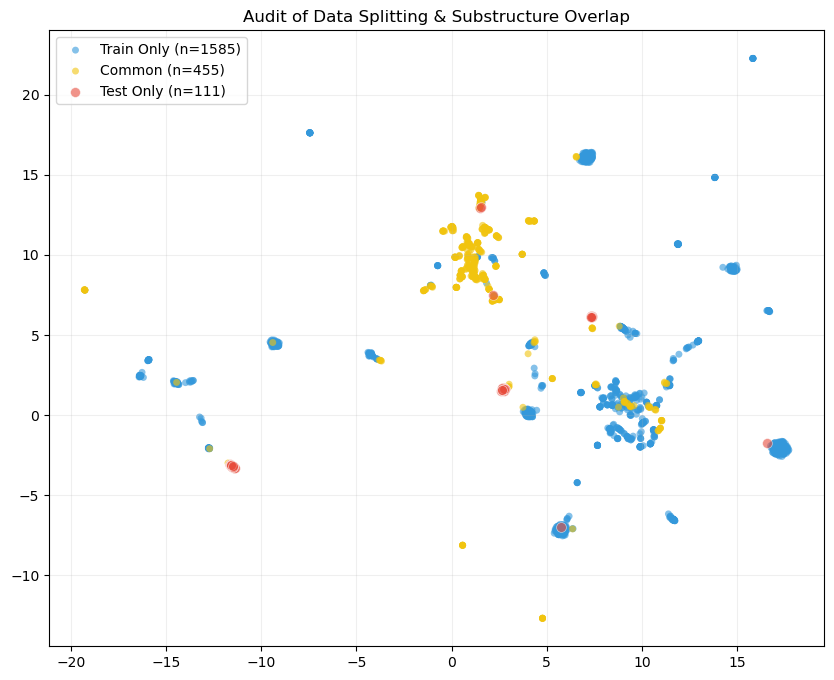

CPU times: total: 2min 40s
Wall time: 47.6 s


In [7]:
%%time
save_name = str(Path(FIG_SAVE_PATH,f'Random_split_by_NPs'))

all_np_ind = np.arange(WEIGHTS_MATRIX.shape[0])
ind_tr, ind_te = train_test_split(all_np_ind, test_size=0.20, random_state=42)

train_np_sizes = NP_SIZES[ind_tr]
test_np_sizes = NP_SIZES[ind_te]

tr_sub_ind = np.where(WEIGHTS_MATRIX[ind_tr]>0)[1].tolist()
te_sub_ind = np.where(WEIGHTS_MATRIX[ind_te]>0)[1].tolist()

train_sub_sizes = SUB_SIZES[tr_sub_ind]
test_sub_sizes = SUB_SIZES[te_sub_ind]
sub_ks_stat_ts, sub_p_value_ts = ks_2samp(train_sub_sizes, test_sub_sizes, alternative='two-sided', method='asymp')
sub_ks_stat_gr, sub_p_value_gr = ks_2samp(train_sub_sizes, test_sub_sizes, alternative='greater', method='asymp')

print(f"Тест Колмогорова-Смирнова  для размеров НК (Train==Test): {sub_ks_stat_ts:.5f} | P-value: {sub_p_value_ts:.5f}")
print(f"Тест Колмогорова-Смирнова  для размеров НК (Train>=Test): {sub_ks_stat_gr:.5f} | P-value: {sub_p_value_gr:.5f}")

np_ks_stat_ts, np_p_value_ts = ks_2samp(train_np_sizes, test_np_sizes, alternative='two-sided', method='asymp')
np_ks_stat_gr, np_p_value_gr = ks_2samp(train_np_sizes, test_np_sizes, alternative='greater', method='asymp')
print(f"Тест Колмогорова-Смирнова  для размеров НЧ (Train==Test): {np_ks_stat_ts:.5f} | P-value: {np_p_value_ts:.5f}")
print(f"Тест Колмогорова-Смирнова  для размеров НЧ (Train>=Test): {np_ks_stat_gr:.5f} | P-value: {np_p_value_gr:.5f}")

print(f'Число уникальных подструктур задействованных в трейн части = {len(set(tr_sub_ind))}')
print(f'Число уникальных подструктур задействованных в тест части = {len(set(te_sub_ind))}')
print(f'Число уникальных подструктур из тест части не встречающихся в трейне = {len(set(te_sub_ind)-set(tr_sub_ind))}')
print(f'Число уникальных подструктур из трейн части не встречающихся в тесте = {len(set(tr_sub_ind)-set(te_sub_ind))}')

X_tr, y_tr = factory.generate_experiment_data(NORMALISED_WEIGHTS[ind_tr], aug_params=None)
X_te, y_te = factory.generate_experiment_data(NORMALISED_WEIGHTS[ind_te], aug_params=None)

plot_dataset_variability(X_data=X_tr, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Random split by NP train",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_te, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Random split by NP test",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_tr,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_te,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=WEIGHTS_MATRIX, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='dice', 
                        save_name=save_name+'_dice')


plot_substructure_audit(weights_matrix=WEIGHTS_MATRIX, 
                        train_sample_idx=ind_tr, 
                        test_sample_idx=ind_te, 
                        metric='cosine', 
                        save_name=save_name+'_cosine')

### Сценарий 3: Разбиение с помощью lauvian_communities без резервирования малых НЧ для трейна

СТАТИСТИКА СООБЩЕСТВ И РАЗБИЕНИЯ ВЫБОРКИ:
Объектов в Train: 684 | Объектов в Test: 116
Размер базиса подструктур: 2151 | Пересекающиеся подструктуры: 461 (21.4%)
Уникально подструктур в Train: 1042 | Уникально в Test: 648
Доля Test выборки внутри интервала [0.03,0.97] Train данных: 0.672
Кол-во краевых малых НЧ в Test выборке (ниже 0.03 квантиля Train): 36
Кол-во краевых крупных НЧ в Test выборке (выше 0.97 квантиля Train): 2
Находятся ли краевые значения Test данных полностью внутри Train данных: False
Тест Колмогорова-Смирнова  для размеров НЧ (Train==Test): 0.39696 | P-value: 0.00000
Тест Колмогорова-Смирнова  для размеров НЧ (Train>=Test): 0.00862 | P-value: 0.97890
Тест Колмогорова-Смирнова  для размеров НК (Train==Test): 0.09534 | P-value: 0.00011
Тест Колмогорова-Смирнова  для размеров НК (Train>=Test): 0.09534 | P-value: 0.00005


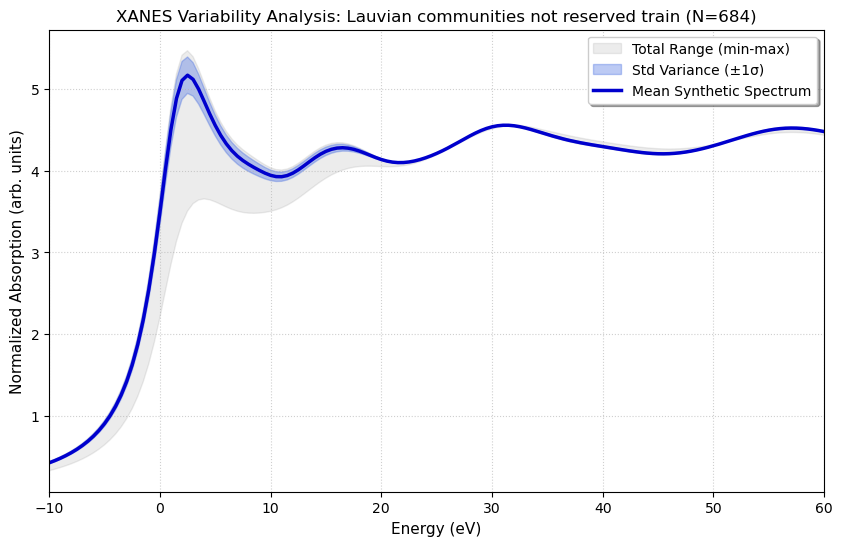

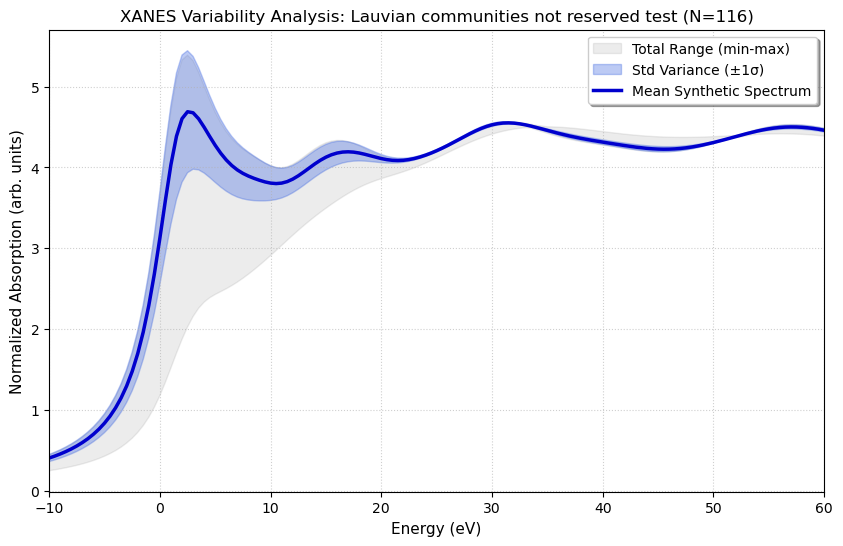

Y_train:


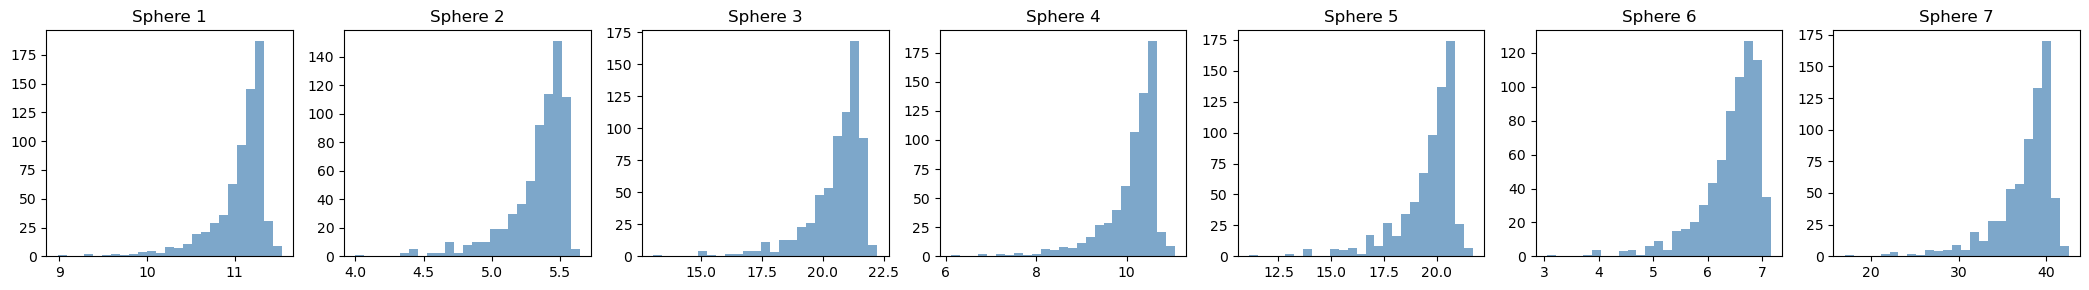

Y_test:


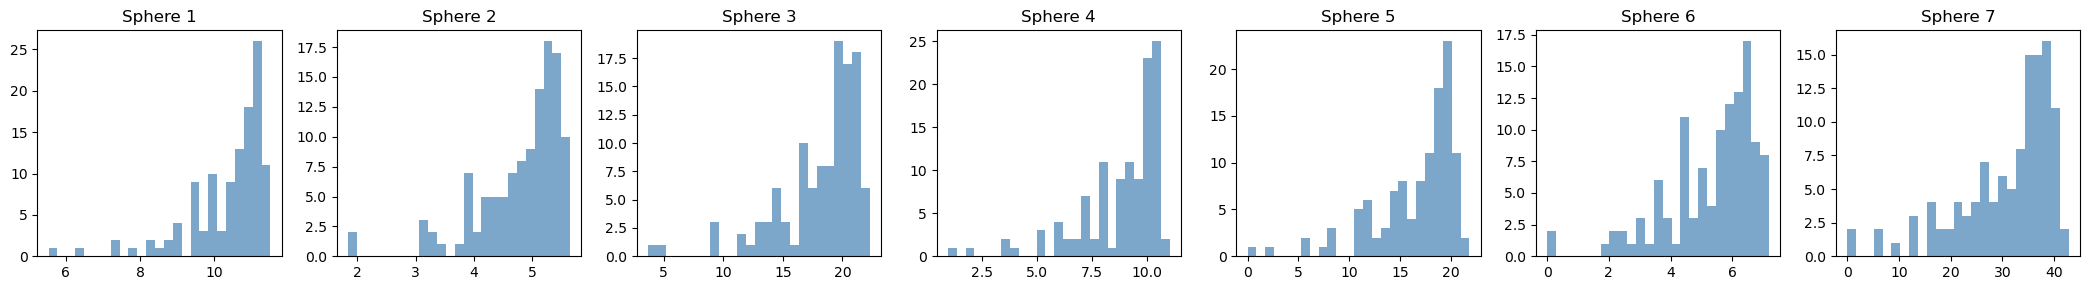

Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


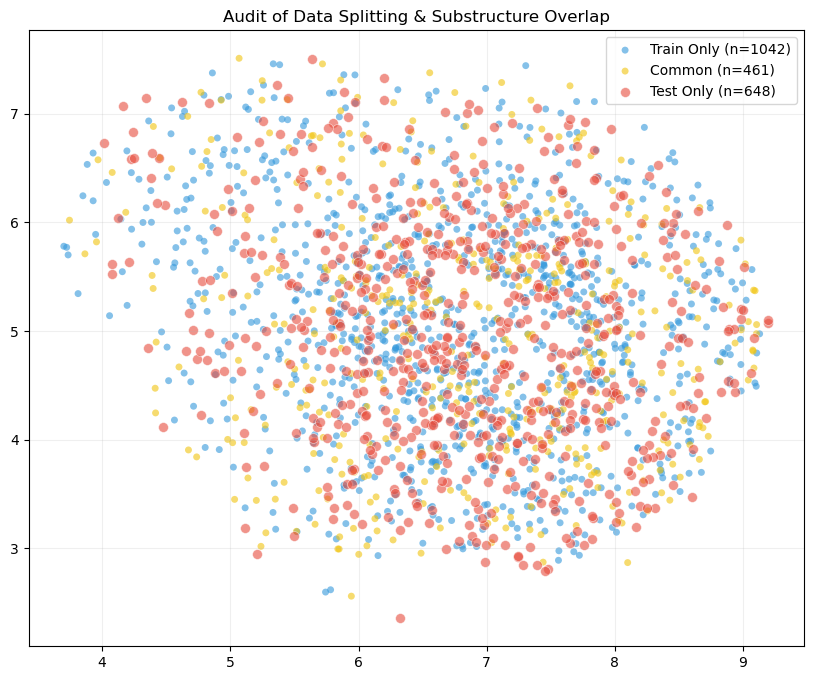

Запуск UMAP (может занять время)...


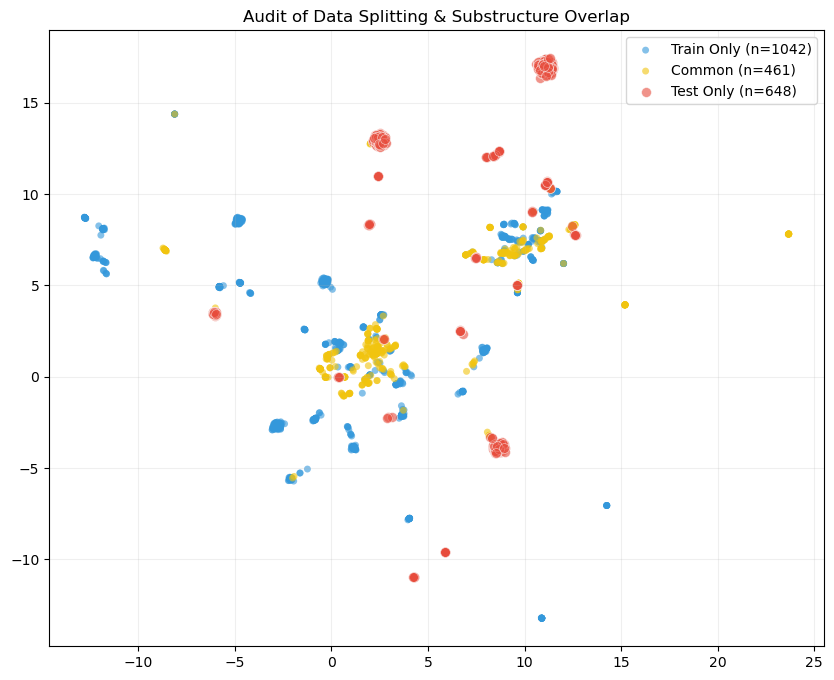

CPU times: total: 2min 44s
Wall time: 50.3 s


In [8]:
%%time
save_name = str(Path(FIG_SAVE_PATH,f'Lauvian_split_not_reserved'))
tr_samp_idx, te_samp_idx, tr_sub_ids_idx, te_sub_ids_idx = factory.get_community_split(weights_matrix=WEIGHTS_MATRIX, 
                                                                                       resolution=2.5, 
                                                                                       threshold=0.75, 
                                                                                       guaranteed_train_samples_idx=None,
                                                                                       sub_sizes=SUB_SIZES,
                                                                                       seed=42)


X_tr, y_tr = factory.generate_experiment_data(NORMALISED_WEIGHTS[tr_samp_idx], aug_params=None)
X_te, y_te = factory.generate_experiment_data(NORMALISED_WEIGHTS[te_samp_idx], aug_params=None)


plot_dataset_variability(X_data=X_tr, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Lauvian communities not reserved train",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_te, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Lauvian communities not reserved test",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_tr,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_te,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=WEIGHTS_MATRIX, 
                        train_sample_idx=tr_samp_idx, 
                        test_sample_idx=te_samp_idx, 
                        metric='dice', 
                        save_name=save_name+'_dice')


plot_substructure_audit(weights_matrix=WEIGHTS_MATRIX, 
                        train_sample_idx=tr_samp_idx, 
                        test_sample_idx=te_samp_idx, 
                        metric='cosine', 
                        save_name=save_name+'_cosine')

### Сценарий 4: Разбиение с помощью lauvian_communities c резервирования малых НЧ для трейна


Компонента №0 (Размер группы подструктур: 3)
  -> Идексы подструктур: [0, 292, 293]
  -> Кол-ва атомов в подструктурах: [18 19 19]
  -> Встречается в наночастицах под индексами [24] 
  -> Кол-ва атомов в наночастицах [19]

Компонента №2 (Размер группы подструктур: 5)
  -> Идексы подструктур: [2, 586, 686, 1967, 1882]
  -> Кол-ва атомов в подструктурах: [46 55 54 35 41]
  -> Встречается в наночастицах под индексами [26] 
  -> Кол-ва атомов в наночастицах [55]

Компонента №3 (Размер группы подструктур: 2)
  -> Идексы подструктур: [540, 541]
  -> Кол-ва атомов в подструктурах: [13 13]
  -> Встречается в наночастицах под индексами [23] 
  -> Кол-ва атомов в наночастицах [13]

Компонента №4 (Размер группы подструктур: 4)
  -> Идексы подструктур: [1272, 1409, 2043, 2044]
  -> Кол-ва атомов в подструктурах: [34 38 43 43]
  -> Встречается в наночастицах под индексами [25 63] 
  -> Кол-ва атомов в наночастицах [43 43]
СТАТИСТИКА НАБОРА ИНДЕКСОВ (TRAIN):
Всего объектов в weights_matrix: 800
Баз

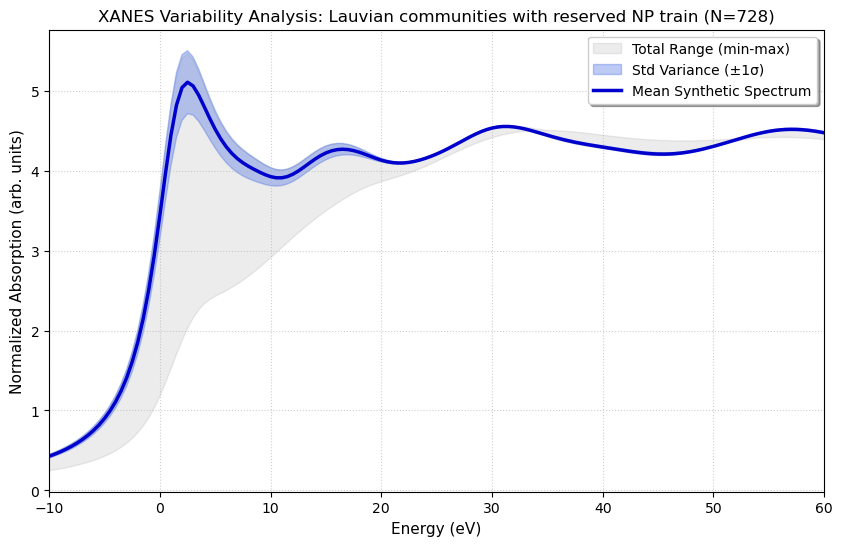

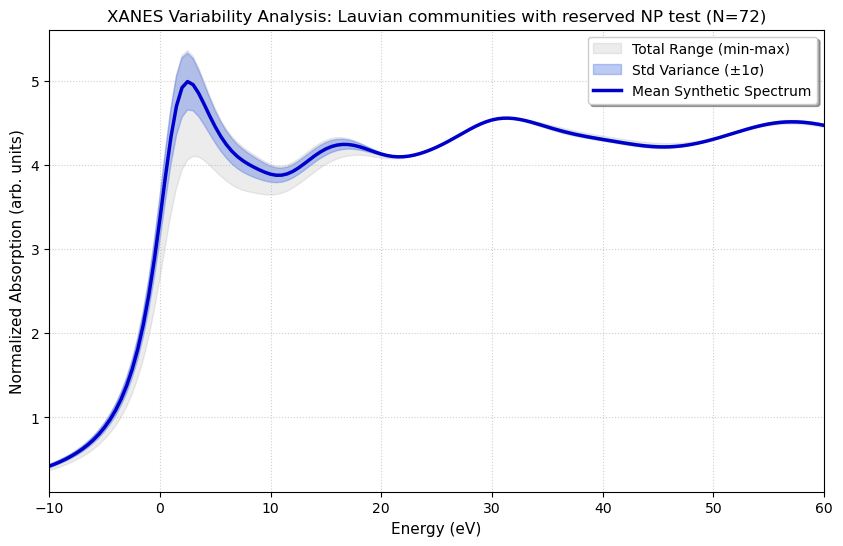

Y_train:


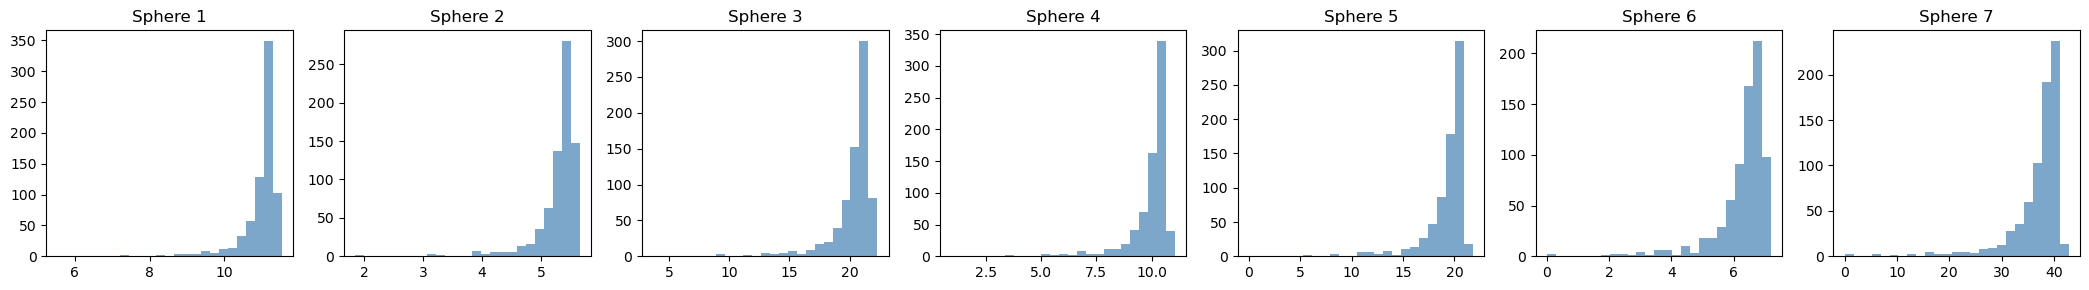

Y_test:


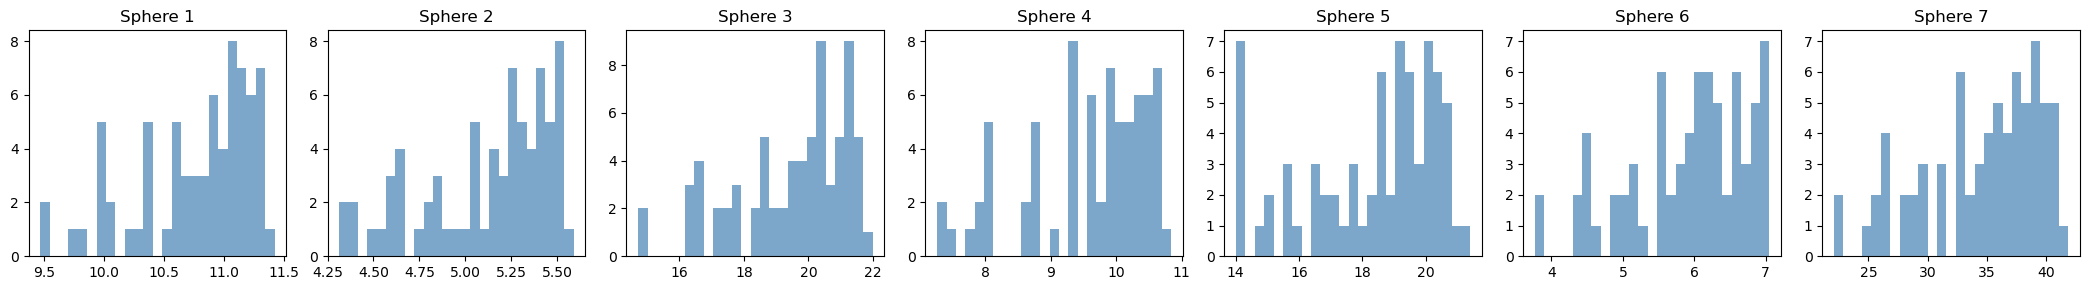

Запуск UMAP (может занять время)...


F:\Conda\envs\MatML\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for dice distance metric; inverse_transform will be unavailable
  warn(


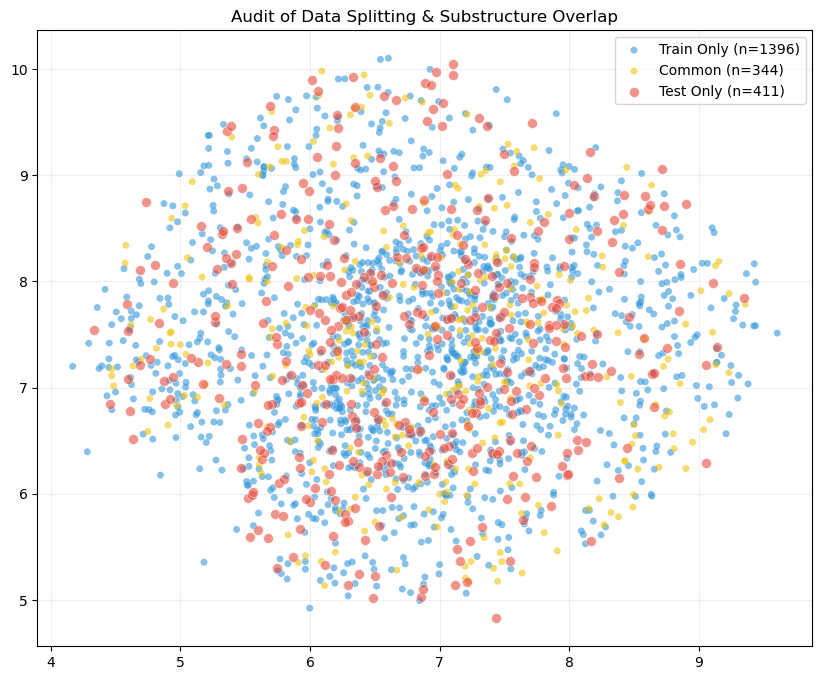

Запуск UMAP (может занять время)...


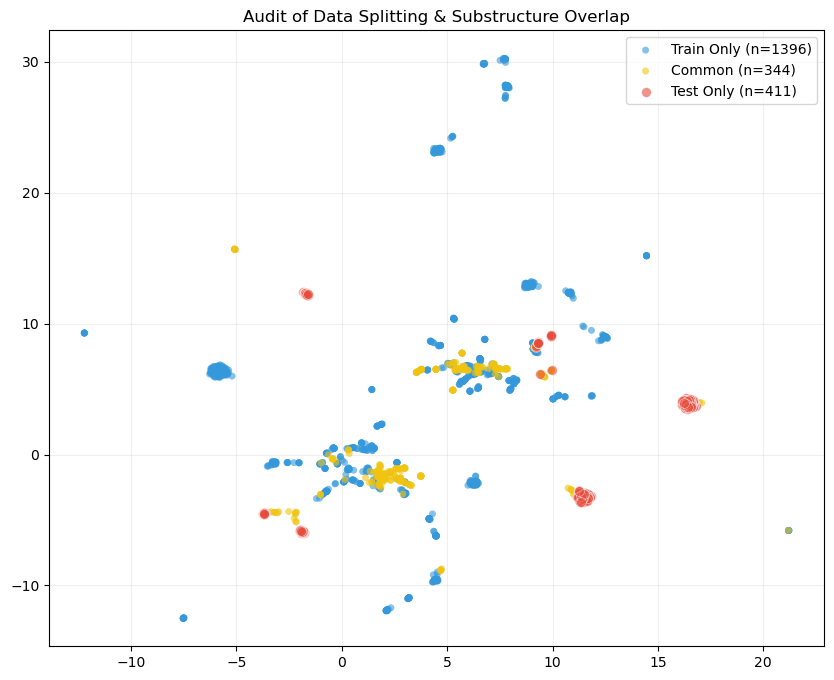

CPU times: total: 2min 40s
Wall time: 48 s


In [9]:
%%time
save_name = str(Path(FIG_SAVE_PATH,f'Lauvian_split_with_reserved_NP'))

guaranteed_train_samples_idx = get_preserved_mask(weights_matrix=WEIGHTS_MATRIX,
                                                  sub_sizes=SUB_SIZES,
                                                  reconstruction_n_comp=2,        # Число компонент для PCA оценки ошибки реконструкции
                                                  reconstruction_top_repcent=3.0, # сколько топ % брать 
                                                  low_size_percentile=3.0,        # сколько % самых малых НЧ брать
                                                  high_size_percentile=0.1,       # сколько % самых крупных НЧ брать
                                                  masks_priorities=[3,2,1,0],     # [con_comp, recon_err, low_prc, high_prc]
                                                  max_base_percentile=5.0,        # Допустимый % данных для отобранных НЧ
                                                  max_tail_percentile=3.0,        # Допустимый процент "хвоста" для отобранных данных
                                                  tail_threshold=0.65,            # Порог вовлеченности подструктур чтобы затянуть в трейн
                                                  verbose=1, 
                                                  seed=42)

tr_samp_idx, te_samp_idx, tr_sub_ids_idx, te_sub_ids_idx = factory.get_community_split(weights_matrix=WEIGHTS_MATRIX, 
                                                                                       resolution=2.5, 
                                                                                       threshold=0.75, 
                                                                                       guaranteed_train_samples_idx=guaranteed_train_samples_idx,
                                                                                       sub_sizes=SUB_SIZES,
                                                                                       seed=42)


X_tr, y_tr = factory.generate_experiment_data(NORMALISED_WEIGHTS[tr_samp_idx], aug_params=None)
X_te, y_te = factory.generate_experiment_data(NORMALISED_WEIGHTS[te_samp_idx], aug_params=None)


plot_dataset_variability(X_data=X_tr, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Lauvian communities with reserved NP train",
                         save_name=save_name+'_train_spectra_var'
                        )

plot_dataset_variability(X_data=X_te, 
                         energy_grid=factory.energy_grid, 
                         foil_spectrum=None,
                         title_suffix=f"Lauvian communities with reserved NP test",
                         save_name=save_name+'_test_spectra_var'
                        )

print('Y_train:')
plot_cn_distribution(y_matrix=y_tr,save_name=save_name+'_train_cn_var')
print('Y_test:')
plot_cn_distribution(y_matrix=y_te,save_name=save_name+'_test_cn_var')

plot_substructure_audit(weights_matrix=WEIGHTS_MATRIX, 
                        train_sample_idx=tr_samp_idx, 
                        test_sample_idx=te_samp_idx, 
                        metric='dice', 
                        save_name=save_name+'_dice')


plot_substructure_audit(weights_matrix=WEIGHTS_MATRIX, 
                        train_sample_idx=tr_samp_idx, 
                        test_sample_idx=te_samp_idx, 
                        metric='cosine', 
                        save_name=save_name+'_cosine')

### Выводы

* При разбиении данных на уровне всех доступных подструктур (сценарий 1) видно, что распределения X и y с хорошей точностью совпадают,
  однако, не остается таких подструктур, которые бы не увидела "модель" во время обучения, что может приводить к утечке данных и
  неспособности адекватно оценить ее обобщающую способность.
* Случайное разбиение на уровне НЧ (сценарий 2) демонстрирует близкие распределения векторов CN и более выраженные различия в спектрах,
  при этом имеется маленький запас подструктур которые не видела "модель", но такой результат не является гарантированным.
* Разбиение данных на уровне подструктур с помощью Lauvian_communities без жесткой резервации малых НЧ за Train выборкой демонстрирует заметные
  расхождения как в спектрах так и распределениях CN, но сохраняет достаточно большое кол-во подструктур не засвеченных в трейне.
  Расхождения в данных обусловленно тем фактом, что в процессе разбиения, малые НЧ представленные достаточно изолированными подграфами уходят в test.
* Оптимальным вариантом выглядит использование Lauvian_communities с резервированием краевых НЧ реализованны, такой подход дает близкие спектры, и более широкий диапазон значений CN для трейн выборки.
* Важно чтобы доля подструктур не встречающаяся в Train данных была большой, т.к. при генерации "синтетических" данных, их кол-во не может быть увеличенно.